# Graficas Análisis Flares T - EM

## Packages

In [1]:
from datetime import datetime, timedelta
import pandas as pd
import os
from sunpy.net import Fido, attrs as a
from sunpy.timeseries import TimeSeries
from sunpy.timeseries.sources.goes import XRSTimeSeries
import astropy.units as u
from sunkit_instruments.goes_xrs import calculate_temperature_em
import matplotlib.pyplot as plt
import numpy as np
from sunpy.data import manager
import netCDF4 as nc
import os
import pandas as pd
from datetime import datetime, timedelta
import copy
from matplotlib import colormaps
list(colormaps)
#from colorspacious import cspace_converter
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import cm
from matplotlib.colors import ListedColormap
import matplotlib.dates as mdates
from matplotlib.ticker import LogFormatter
from matplotlib.ticker import LogFormatterMathtext
from matplotlib.ticker import ScalarFormatter
from matplotlib.ticker import FuncFormatter
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import seaborn as sns
import re
import glob
from matplotlib.ticker import MaxNLocator

/Users/nohoraprieto/miniforge3/envs/sunpy/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Parameters

In [2]:
# ============================================================
# 1. PARÁMETROS DEL ANÁLISIS
# ============================================================
n=16752
new_n = 8164 # nuevo número de días
fecha_actual = "2025-12-01"
# Parámetros de FAI
window_minutes=30
fai_temp_range = (8, 35)
fai_em_jump = 0.001
fai_em_threshold_d=fai_em_jump
date_column = "date"
duration = True
FAI_duration = 4
exclude_last_minutes = 20 # minutos al final del día para excluir FAIs
filter_flare_coincidence = True
method = "filteredend_nooverlap" # "all", "true", "filtered", "filteredend" o "filteredend_nooverlap"
flares="ABCMX" # "valid", "no_A", "no_A_B", 
                                  # "no_A_B_nonoverlap" o "no_A_B_nonoverlap_wstart"
                                  # "M_X_nonoverlap_wstart"
nooverlap = True
min_gap_minutes_overlap = 20 #FILTRO EXTRA: remover FAI que ocurren tras un flare en [end, end + min_gap_minutes_overlap] 

# Formato de threshold para nombres de carpetas
threshold_str = f"{fai_em_jump}"   # "0.005" # convertir a string sin notación científica
fai_em_threshold_d = threshold_str.replace(".", "d") # reemplazar el punto por 'd'

## Folders

In [ ]:
analysis_dir = os.path.join(f"Data_for_{n}_days/Analysis_FAI")
# Crear carpeta de análisis (si no existe) y mostrar mensaje
if os.path.exists(analysis_dir ):
    print(f"⚠️ La carpeta de análisis ya existía: {analysis_dir }")
else:
    os.makedirs(analysis_dir , exist_ok=True)
    print(f"📁 Carpeta de análisis creada: {analysis_dir}")

# Crear subcarpeta para guardar resultados de análisis
analysis_esp = os.path.join(analysis_dir, f"Analysis_FAI_{flares}_T{fai_temp_range[0]}-{fai_temp_range[1]}_dEM{fai_em_threshold_d}_dur{FAI_duration}min")
# Crear carpeta de análisis (si no existe) y mostrar mensaje
if os.path.exists(analysis_esp ):
    print(f"⚠️ La carpeta de análisis ya existía: {analysis_esp }")
else:
    os.makedirs(analysis_esp , exist_ok=True)
    print(f"📁 Carpeta de análisis creada: {analysis_esp}")

⚠️ La carpeta de análisis ya existía: Data_for_16752_days/Flare_analysis_graphs_8164


## Valid data

In [4]:
output_dir = f"Data_for_{n}_days"

# Path of cleaned data in csv
csv_path_full_valid = f"{output_dir}/df_full_{new_n}_valid.csv"
# Path of valid flares: 
csv_path_flares = f"{output_dir}/df_flares_{new_n}_{flares}.csv"
# Path of df_full
csv_path_full = f"{output_dir}/all_df_full_{n}.csv"

# Verificar existencia de archivos y avisar
if not os.path.exists(csv_path_full_valid):
    print(f"⚠️ No se encontró el archivo GOES: {csv_path_full_valid}")
else:
    print(f"✅ Archivo GOES encontrado: {csv_path_full_valid}")

if not os.path.exists(csv_path_flares):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_flares}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_flares}")

if not os.path.exists(csv_path_full):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_full}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_full}")

df_full_valid = pd.read_csv(csv_path_full_valid)
df_flares_valid = pd.read_csv(csv_path_flares)
df_full = pd.read_csv(csv_path_full)

✅ Archivo GOES encontrado: Data_for_16752_days/df_full_8164_valid.csv
✅ Archivo de flares encontrado: Data_for_16752_days/df_flares_8164_ABCMX.csv
✅ Archivo de flares encontrado: Data_for_16752_days/all_df_full_16752.csv


## Functions

In [5]:

def plot_temp_em_distribution_for_class(
    df_full,
    df_flares,
    flare_class=None,        # Ej: "X", "M", "C" o None para todos
    time_column="PeakTime",  # "StartTime" o "PeakTime"
    T_col="T_cor",
    EM_col="EM_cor_norm",
    bins_T=30,
    bins_EM=30,
    graphics_dir=".",
    save_plot=True,
    plot_name=None,
    class_col="Class"
):
    """
    Distribuciones de T y EM en un instante característico de flares,
    opcionalmente filtrando por clase de flare.
    """

    df = df_full.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")

    df_flares = df_flares.copy()
    df_flares[time_column] = pd.to_datetime(df_flares[time_column])

    # Filtrar por clase si se indicó
    if flare_class is not None:
        df_flares = df_flares[df_flares[class_col] == flare_class]
        title_suffix = f" (Class {flare_class})"
    else:
        title_suffix = " (All classes)"

    T_vals, EM_vals = [], []

    for _, flare in df_flares.iterrows():
        flare_time = flare[time_column]
        if flare_time not in df.index:
            continue
        row = df.loc[flare_time]
        if pd.notna(row[T_col]) and pd.notna(row[EM_col]):
            T_vals.append(row[T_col])
            EM_vals.append(row[EM_col])

    T_vals = np.array(T_vals)
    EM_vals = np.array(EM_vals)

    plt.rcParams.update({
        "axes.titlesize": 22, # título de cada subplot
        "axes.labelsize": 20, # etiquetas de ejes
        "xtick.labelsize": 20,# etiquetas de ticks x
        "ytick.labelsize": 20 # etiquetas de ticks y
    })
   

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

    # --- Temperatura ---
    if len(T_vals) > 0:
        axes[0].hist(T_vals, bins=bins_T, histtype="stepfilled", alpha=0.75)
        axes[0].set_xlim(0, np.nanpercentile(T_vals, 99))
        axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))  # <-- solo enteros
    else:
        axes[0].text(0.5, 0.5, "No data for this selection", ha='center', va='center', transform=axes[0].transAxes)
        axes[0].set_xlim(0, 1)
        axes[0].set_ylim(0, 1)
    axes[0].set_xlabel("Temperature [MK]")
    axes[0].set_ylabel("Counts")
    axes[0].set_title(f"Temperature distribution at {time_column}{title_suffix}")

    # --- EM ---
    if len(EM_vals) > 0:
        bins_em = np.logspace(np.log10(EM_vals.min()), np.log10(EM_vals.max()), bins_EM)
        axes[1].hist(EM_vals, bins=bins_em)
        axes[1].set_xscale("log")
        axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))  # <-- solo enteros
    else:
        axes[1].text(0.5, 0.5, "No data for this selection", ha='center', va='center', transform=axes[1].transAxes)
        axes[1].set_xlim(0, 1)
        axes[1].set_ylim(0, 1)
        axes[1].set_xscale("linear")

    axes[1].set_xlabel(r"Emission Measure [cm$^{-3}$]")
    axes[1].set_ylabel("Counts")
    axes[1].set_title(f"EM distribution at {time_column}{title_suffix}")

    # ---------------------------
    # Guardar figura
    # ---------------------------
    if plot_name is None:
        name_class = flare_class if flare_class is not None else "all"
        plot_name = f"temp_em_{name_class}_{time_column}.png"

    if save_plot:
        output_path = os.path.join(graphics_dir, plot_name)
        plt.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved: {graphics_dir}/{plot_name}")

    plt.show()
    return fig, T_vals, EM_vals

#

## test 1

Figure saved: Data_for_16752_days/Flare_analysis_graphs_8164/temp_em_X_StartTime.png


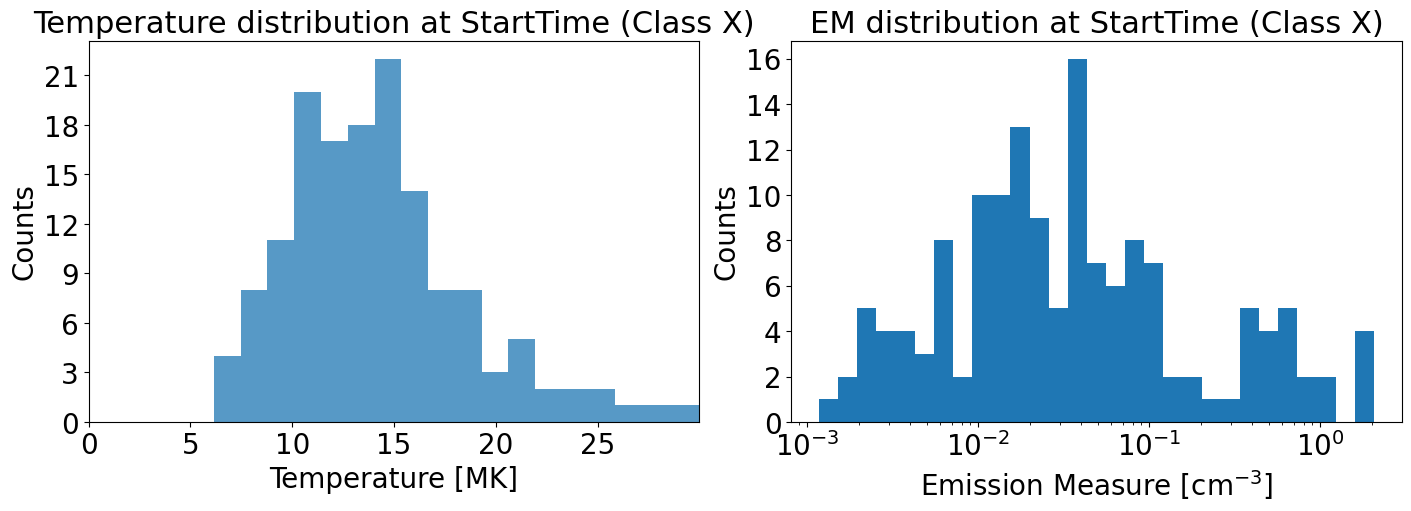

In [6]:
fig, T_vals_X, EM_vals_X = plot_temp_em_distribution_for_class(
    df_full=df_full_valid,
    df_flares=df_flares_valid,
    flare_class="X",
    time_column="StartTime",
    graphics_dir=analysis_dir,
    save_plot=True,
    plot_name=None,
    class_col="ClassLetter")

## Test 2

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from matplotlib.ticker import MaxNLocator
import os


In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from matplotlib.ticker import MaxNLocator

def plot_temp_distribution_by_class(
    df_full,
    df_flares,
    classes=("A", "B", "C", "M", "X"),  # Clases a comparar
    time_column="PeakTime",
    T_col="T_cor",
    graphics_dir=".",
    save_plot=True,
    plot_name=None,
    class_col="Class"
):
    """
    Comparación de distribuciones de temperatura para varias clases de flares.
    Cada clase tiene su propio eje Y (densidad), pero comparten el mismo eje X (temperatura).
    
    Devuelve:
        fig: la figura de matplotlib
        T_by_class: diccionario {clase: array de temperaturas}
    """

    # --- Preparar datos ---
    df = df_full.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")

    df_flares = df_flares.copy()
    df_flares[time_column] = pd.to_datetime(df_flares[time_column])

    T_by_class = {}  # diccionario para guardar temperaturas por clase

    # --- Crear figura ---
    fig, axes = plt.subplots(
        len(classes), 1,
        figsize=(10, 10),
        sharex=True,
        constrained_layout=True
    )

    if len(classes) == 1:
        axes = [axes]

    # --- Plot por clase ---
    for ax, flare_class in zip(axes, classes):

        df_class = df_flares[df_flares[class_col] == flare_class]

        T_vals = []
        for _, flare in df_class.iterrows():
            flare_time = flare[time_column]
            if flare_time in df.index:
                T = df.loc[flare_time, T_col]
                if pd.notna(T):
                    T_vals.append(T)

        T_vals = np.array(T_vals)
        T_by_class[flare_class] = T_vals

        if len(T_vals) < 2:
            ax.text(0.5, 0.5, "Not enough data",
                    ha="center", va="center", transform=ax.transAxes)
            ax.set_ylim(0, 1)
            continue

        # --- KDE ---
        kde = gaussian_kde(T_vals)
        T_grid = np.linspace(T_vals.min(), T_vals.max(), 500)
        density = kde(T_grid)

        ax.plot(T_grid, density, linewidth=2)
        ax.fill_between(T_grid, density, alpha=0.3)

        # --- Eje Y ---
        ax.set_ylabel(f"{flare_class}", rotation=0, labelpad=20, fontsize=14)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.tick_params(axis="y", labelsize=12)

    # --- Eje X compartido ---
    axes[-1].set_xlabel("Temperature [MK]", fontsize=16)

    # --- Títulos ---
    fig.suptitle(
        f"Temperature distributions at {time_column} (KDE) by flare class",
        fontsize=18
    )

    # --- Guardar ---
    if plot_name is None:
        plot_name = f"temp_kde_by_class_{time_column}.png"

    if save_plot:
        output_path = os.path.join(graphics_dir, plot_name)
        plt.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved: {output_path}")

    plt.show()
    return fig, T_by_class


Figure saved: Data_for_16752_days/Flare_analysis_graphs_8164/temp_kde_by_class_StartTime.png


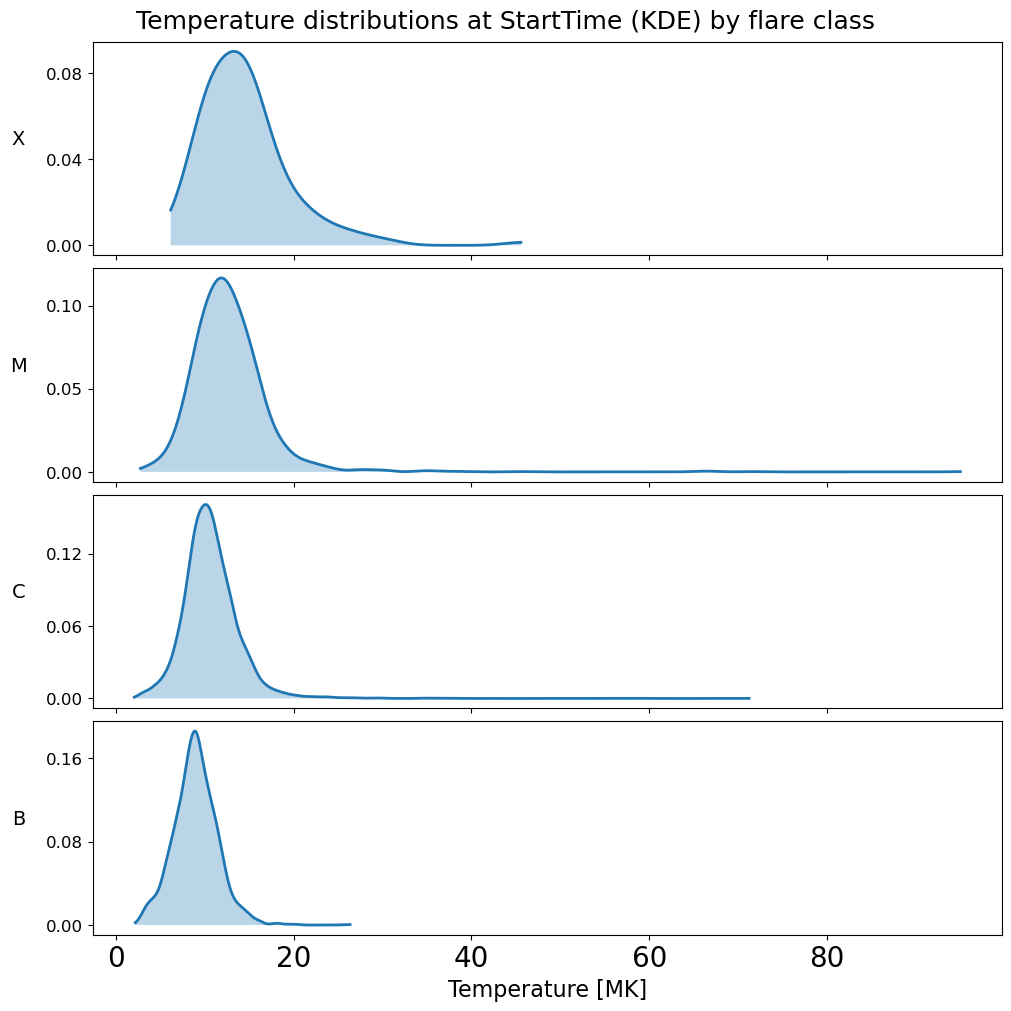

In [9]:
fig, T_by_class = plot_temp_distribution_by_class(
    df_full=df_full_valid,
    df_flares=df_flares_valid,
    classes=("X", "M", "C", "B"),  # orden descendente de energía
    time_column="StartTime",
    graphics_dir=analysis_dir,
    save_plot=True,
    class_col="ClassLetter"
)

# Para acceder a las temperaturas de clase X:
T_vals_X = T_by_class["X"]



In [10]:
def plot_temp_distribution_by_class(
    df_full,
    df_flares,
    classes=("X", "M", "C", "B", "A"),  # Clases a comparar
    time_column="PeakTime",
    T_col="T_cor",
    graphics_dir=".",
    save_plot=True,
    plot_name=None,
    class_col="Class",
    x_min=None,  # límite mínimo eje X
    x_max=None   # límite máximo eje X
):
    """
    Comparación de distribuciones de temperatura para varias clases de flares.
    Cada clase tiene su propio eje Y (densidad), pero comparten el mismo eje X (temperatura).

    Devuelve:
        fig: la figura de matplotlib
        T_by_class: diccionario {clase: array de temperaturas}
    """

    # --- Preparar datos ---
    df = df_full.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")

    df_flares = df_flares.copy()
    df_flares[time_column] = pd.to_datetime(df_flares[time_column])

    T_by_class = {}  # diccionario para guardar temperaturas por clase

    # --- Crear figura ---
    fig, axes = plt.subplots(
        len(classes), 1,
        figsize=(10, 10),
        sharex=True,
        constrained_layout=True
    )

    if len(classes) == 1:
        axes = [axes]

    # --- Determinar límites automáticos si no se pasan ---
    if x_min is None:
        x_min = min(df[T_col].min(), 0)  # evita valores negativos
    if x_max is None:
        x_max = df[T_col].max()

    # --- Plot por clase ---
    for ax, flare_class in zip(axes, classes):

        df_class = df_flares[df_flares[class_col] == flare_class]

        T_vals = []
        for _, flare in df_class.iterrows():
            flare_time = flare[time_column]
            if flare_time in df.index:
                T = df.loc[flare_time, T_col]
                if pd.notna(T):
                    T_vals.append(T)

        T_vals = np.array(T_vals)
        T_by_class[flare_class] = T_vals

        if len(T_vals) < 2:
            ax.text(0.5, 0.5, "Not enough data",
                    ha="center", va="center", transform=ax.transAxes)
            ax.set_ylim(0, 1)
            continue

        # --- KDE ---
        kde = gaussian_kde(T_vals)
        T_grid = np.linspace(x_min, x_max, 500)
        density = kde(T_grid)

        ax.plot(T_grid, density, linewidth=2)
        ax.fill_between(T_grid, density, alpha=0.3)

        # --- Eje Y ---
        ax.set_ylabel(f"{flare_class}", rotation=0, labelpad=20, fontsize=14)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.tick_params(axis="y", labelsize=12)

    # --- Eje X compartido ---
    axes[-1].set_xlabel("Temperature [MK]", fontsize=16)
    axes[-1].set_xlim(x_min, x_max)

    # --- Títulos ---
    fig.suptitle(
        f"Temperature distributions at {time_column} (KDE) by flare class",
        fontsize=18
    )

    # --- Guardar ---
    if plot_name is None:
        plot_name = f"temp_kde_by_class_{time_column}.png"

    if save_plot:
        output_path = os.path.join(graphics_dir, plot_name)
        plt.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved: {output_path}")

    plt.show()
    return fig, T_by_class


Figure saved: ./temp_kde_by_class_StartTime.png


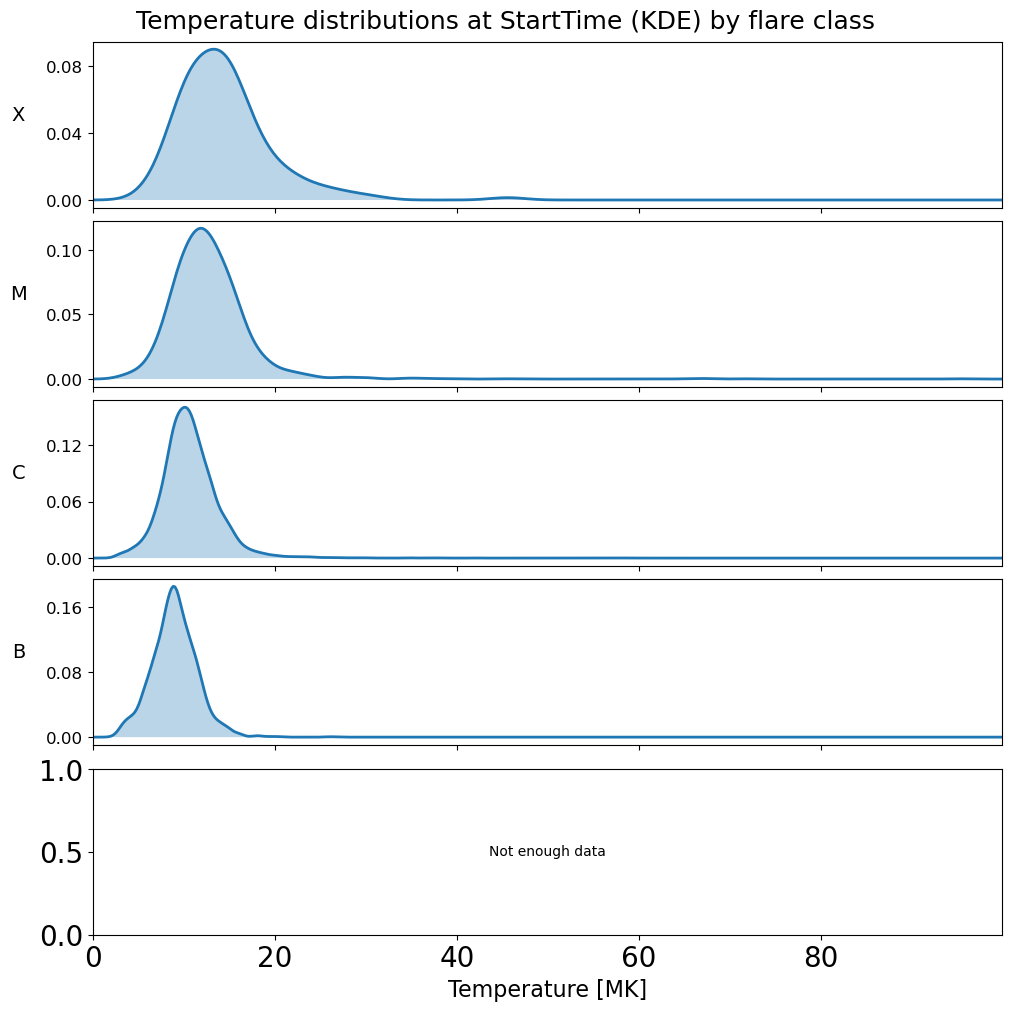

In [11]:
# Automático (por defecto)
fig, T_by_class = plot_temp_distribution_by_class(
    df_full=df_full_valid,
    df_flares=df_flares_valid,
    time_column="StartTime",
    class_col="ClassLetter"
)




Figure saved: ./temp_kde_by_class_PeakTime.png


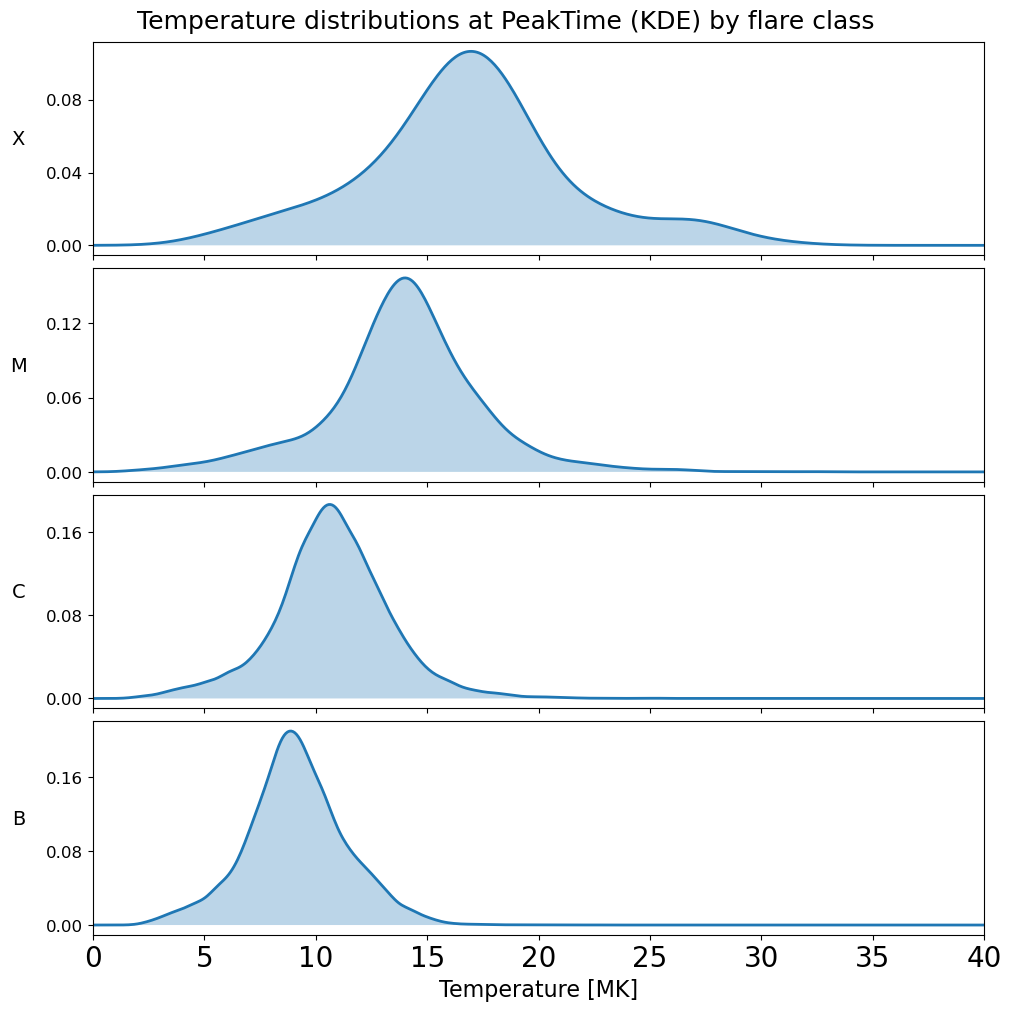

In [12]:
# Con límites específicos
fig, T_by_class = plot_temp_distribution_by_class(
    df_full=df_full_valid,
    df_flares=df_flares_valid,
    classes=("X", "M", "C", "B"),
    time_column="PeakTime",
    class_col="ClassLetter",
    x_min=0,
    x_max=40
)

In [13]:
def plot_temp_counts_by_class(
    df_full,
    df_flares,
    classes=("A", "B", "C", "M", "X"),
    time_column="PeakTime",
    T_col="T_cor",
    bins=30,
    graphics_dir=".",
    save_plot=True,
    plot_name=None,
    class_col="Class",
    x_min=None,
    x_max=None
):
    """
    Comparación de la cantidad de flares por temperatura para distintas clases.
    Se usan histogramas (counts reales) representados como líneas continuas.
    
    Devuelve:
        fig: figura de matplotlib
        T_by_class: diccionario {clase: array de temperaturas}
    """

    # --- Preparar datos ---
    df = df_full.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")

    df_flares = df_flares.copy()
    df_flares[time_column] = pd.to_datetime(df_flares[time_column])

    T_by_class = {}

    # --- Límites automáticos de X ---
    all_T = []
    for flare_class in classes:
        df_class = df_flares[df_flares[class_col] == flare_class]
        for _, flare in df_class.iterrows():
            t = flare[time_column]
            if t in df.index:
                T = df.loc[t, T_col]
                if pd.notna(T):
                    all_T.append(T)

    all_T = np.array(all_T)

    if x_min is None:
        x_min = np.nanmin(all_T)
    if x_max is None:
        x_max = np.nanmax(all_T)

    bins_edges = np.linspace(x_min, x_max, bins + 1)
    bin_centers = 0.5 * (bins_edges[:-1] + bins_edges[1:])

    # --- Crear figura ---
    fig, axes = plt.subplots(
        len(classes), 1,
        figsize=(10, 10),
        sharex=True,
        constrained_layout=True
    )

    if len(classes) == 1:
        axes = [axes]

    # --- Plot por clase ---
    for ax, flare_class in zip(axes, classes):

        df_class = df_flares[df_flares[class_col] == flare_class]

        T_vals = []
        for _, flare in df_class.iterrows():
            flare_time = flare[time_column]
            if flare_time in df.index:
                T = df.loc[flare_time, T_col]
                if pd.notna(T):
                    T_vals.append(T)

        T_vals = np.array(T_vals)
        T_by_class[flare_class] = T_vals

        if len(T_vals) < 2:
            ax.text(0.5, 0.5, "Not enough data",
                    ha="center", va="center", transform=ax.transAxes)
            ax.set_ylim(0, 1)
            continue

        counts, _ = np.histogram(T_vals, bins=bins_edges)

        ax.plot(bin_centers, counts, linewidth=2)
        ax.fill_between(bin_centers, counts, alpha=0.3)

        ax.set_ylabel(f"{flare_class}", rotation=0, labelpad=20, fontsize=14)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.tick_params(axis="y", labelsize=12)

    # --- Eje X ---
    axes[-1].set_xlabel("Temperature [MK]", fontsize=16)
    axes[-1].set_xlim(x_min, x_max)

    # --- Título ---
    fig.suptitle(
        f"Number of flares vs Temperature at {time_column}",
        fontsize=18
    )

    # --- Guardar ---
    if plot_name is None:
        plot_name = f"temp_counts_by_class_{time_column}.png"

    if save_plot:
        output_path = os.path.join(graphics_dir, plot_name)
        plt.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved: {output_path}")

    plt.show()
    return fig, T_by_class


Figure saved: Data_for_16752_days/Flare_analysis_graphs_8164/temp_counts_by_class_PeakTime.png


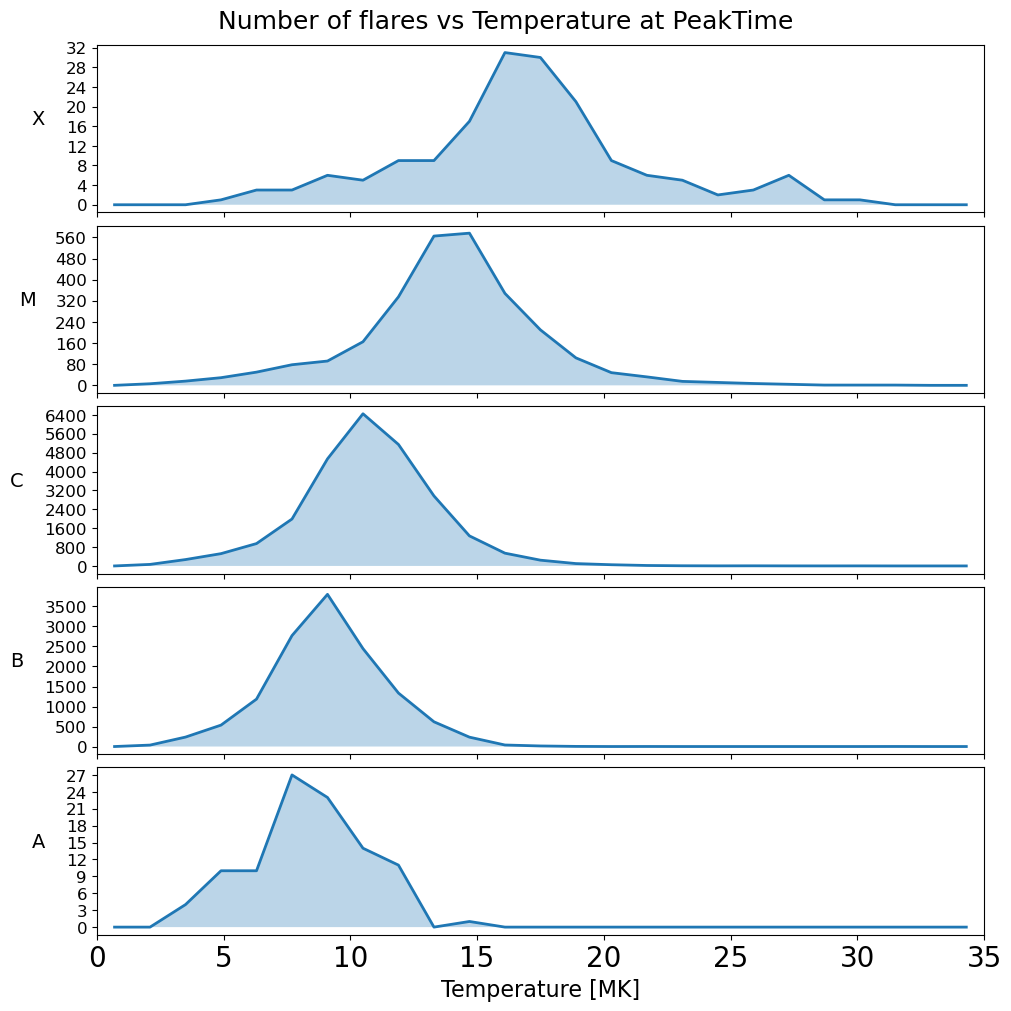

In [14]:
fig, T_by_class = plot_temp_counts_by_class(
    df_full=df_full_valid,
    df_flares=df_flares_valid,
    classes=("X", "M", "C", "B", "A"),
    time_column="PeakTime",
    class_col="ClassLetter",
    bins=25,
    x_min=0,
    x_max=35,
    graphics_dir=analysis_dir
)



Figure saved: Data_for_16752_days/Flare_analysis_graphs_8164/temp_counts_by_class_StartTime.png


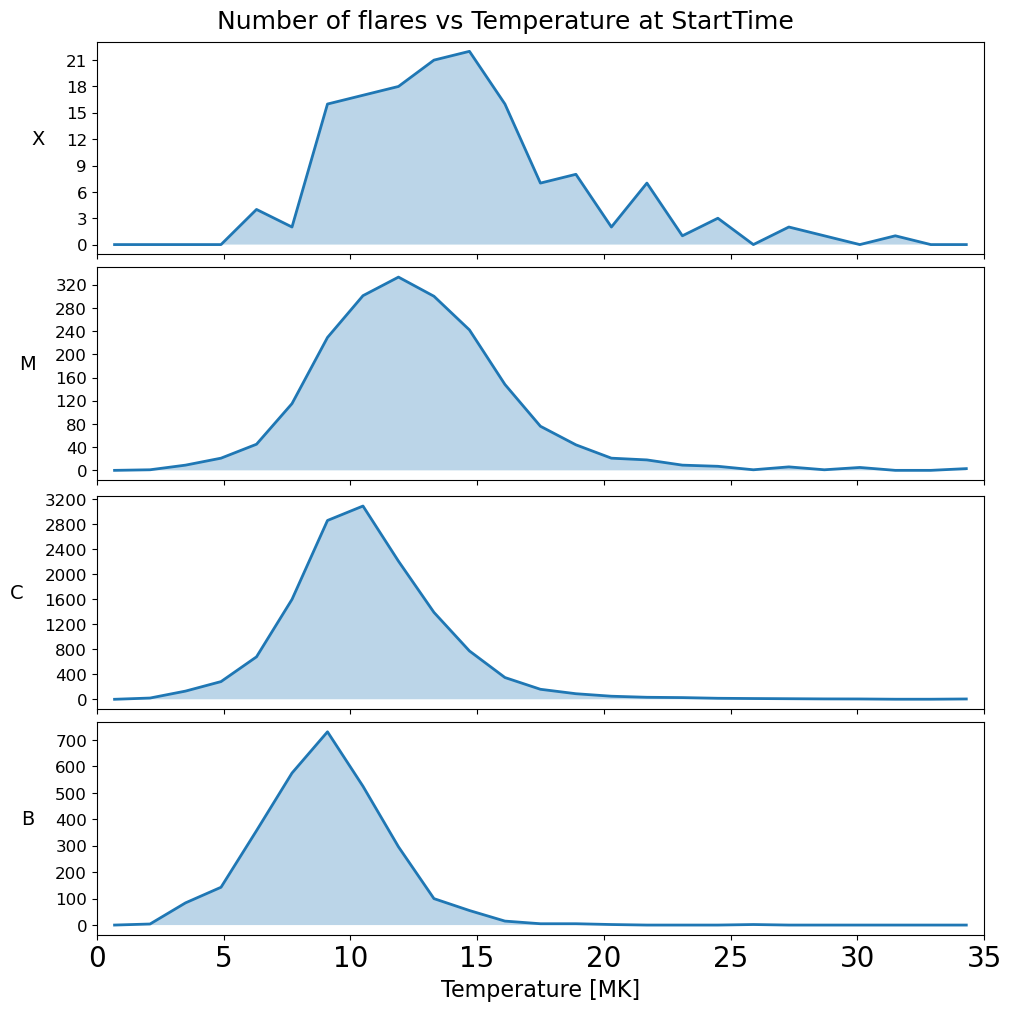

In [15]:
fig, T_by_class = plot_temp_counts_by_class(
    df_full=df_full_valid,
    df_flares=df_flares_valid,
    classes=("X", "M", "C", "B"),
    time_column="StartTime",
    class_col="ClassLetter",
    bins=25,
    x_min=0,
    x_max=35,
    graphics_dir=analysis_dir
)


## función para EM

In [16]:
def plot_em_counts_by_class(
    df_full,
    df_flares,
    classes=("X", "M", "C", "B", "A"),
    time_column="PeakTime",
    EM_col="EM_cor_norm",
    bins=30,
    graphics_dir=".",
    save_plot=True,
    plot_name=None,
    class_col="Class",
    x_min=None,
    x_max=None
):
    """
    Distribución del número de flares en función del Emission Measure (EM),
    una clase debajo de otra, con eje X logarítmico compartido.
    """

    # --- Preparar datos ---
    df = df_full.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")

    df_flares = df_flares.copy()
    df_flares[time_column] = pd.to_datetime(df_flares[time_column])

    EM_by_class = {}

    # --- Crear figura ---
    fig, axes = plt.subplots(
        len(classes), 1,
        figsize=(10, 2.2 * len(classes)),
        sharex=True,
        constrained_layout=True
    )

    if len(classes) == 1:
        axes = [axes]

    # ============================
    # Recolectar EM por clase
    # ============================
    all_EM = []

    for flare_class in classes:
        df_class = df_flares[df_flares[class_col] == flare_class]
        print(flare_class, len(df_class))

        EM_vals = []
        for _, flare in df_class.iterrows():
            flare_time = flare[time_column]

            if flare_time not in df.index:
                continue

            EM = df.loc[flare_time, EM_col]

            if pd.notna(EM):   # 👈 EXACTAMENTE como tu función original
                EM_vals.append(EM)

        EM_vals = np.array(EM_vals)
        EM_by_class[flare_class] = EM_vals

        if len(EM_vals) > 0:
            all_EM.extend(EM_vals)

    # --- Si no hay nada ---
    if len(all_EM) == 0:
        print("No EM data available for selected classes")
        return fig, EM_by_class

    all_EM = np.array(all_EM)

    # --- Límites X ---
    if x_min is None:
        x_min = np.nanmin(all_EM)
    if x_max is None:
        x_max = np.nanmax(all_EM)

    # --- Bins logarítmicos ---
    bins_edges = np.logspace(np.log10(x_min), np.log10(x_max), bins + 1)
    bin_centers = np.sqrt(bins_edges[:-1] * bins_edges[1:])

    # ============================
    # Plot por clase
    # ============================
    for ax, flare_class in zip(axes, classes):

        EM_vals = EM_by_class[flare_class]

        if len(EM_vals) < 2:
            ax.text(
                0.5, 0.5, "Not enough data",
                ha="center", va="center",
                transform=ax.transAxes
            )
            ax.set_ylim(0, 1)
            ax.set_ylabel(flare_class, rotation=0, labelpad=20, fontsize=14)
            continue

        counts, _ = np.histogram(EM_vals, bins=bins_edges)

        ax.plot(bin_centers, counts, linewidth=2)
        ax.fill_between(bin_centers, counts, alpha=0.3)

        ax.set_ylabel(flare_class, rotation=0, labelpad=20, fontsize=14)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.tick_params(axis="y", labelsize=12)
    
        

    # --- Eje X ---
    axes[-1].set_xlabel(r"Emission Measure [cm$^{-3}$]", fontsize=16)
    axes[-1].set_xscale("log")
    axes[-1].set_xlim(x_min, x_max)

    # --- Título ---
    fig.suptitle(
        f"Number of flares vs Emission Measure at {time_column}",
        fontsize=18
    )

    # --- Guardar ---
    if plot_name is None:
        plot_name = f"em_counts_by_class_{time_column}.png"

    if save_plot:
        output_path = os.path.join(graphics_dir, plot_name)
        plt.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved: {output_path}")

    plt.show()
    return fig, EM_by_class


X 223
M 3347
C 28892
B 15412
A 470
Figure saved: ./em_counts_by_class_PeakTime.png


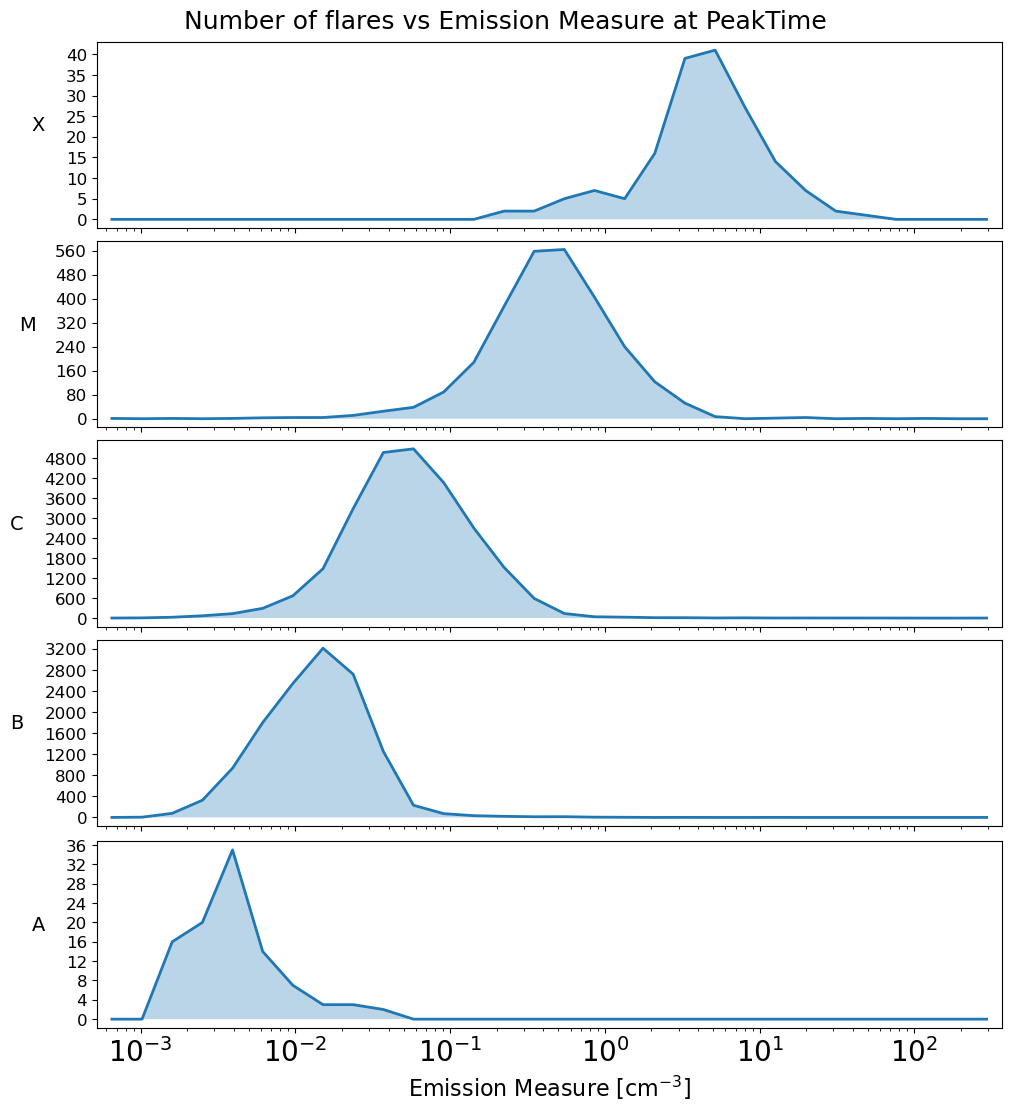

In [17]:
fig, EM_by_class =plot_em_counts_by_class(df_full_valid,
                                            df_flares_valid,
                                            classes=("X", "M", "C", "B", "A"),
                                            time_column="PeakTime",
                                            EM_col="EM_cor_norm",
                                            bins=30,
                                            graphics_dir=".",
                                            save_plot=True,
                                            plot_name=None,
                                            class_col="ClassLetter",
                                            x_min=None,
                                            x_max=None
                                        )

X 223
M 3347
C 28892
B 15412
Figure saved: ./em_counts_by_class_StartTime.png


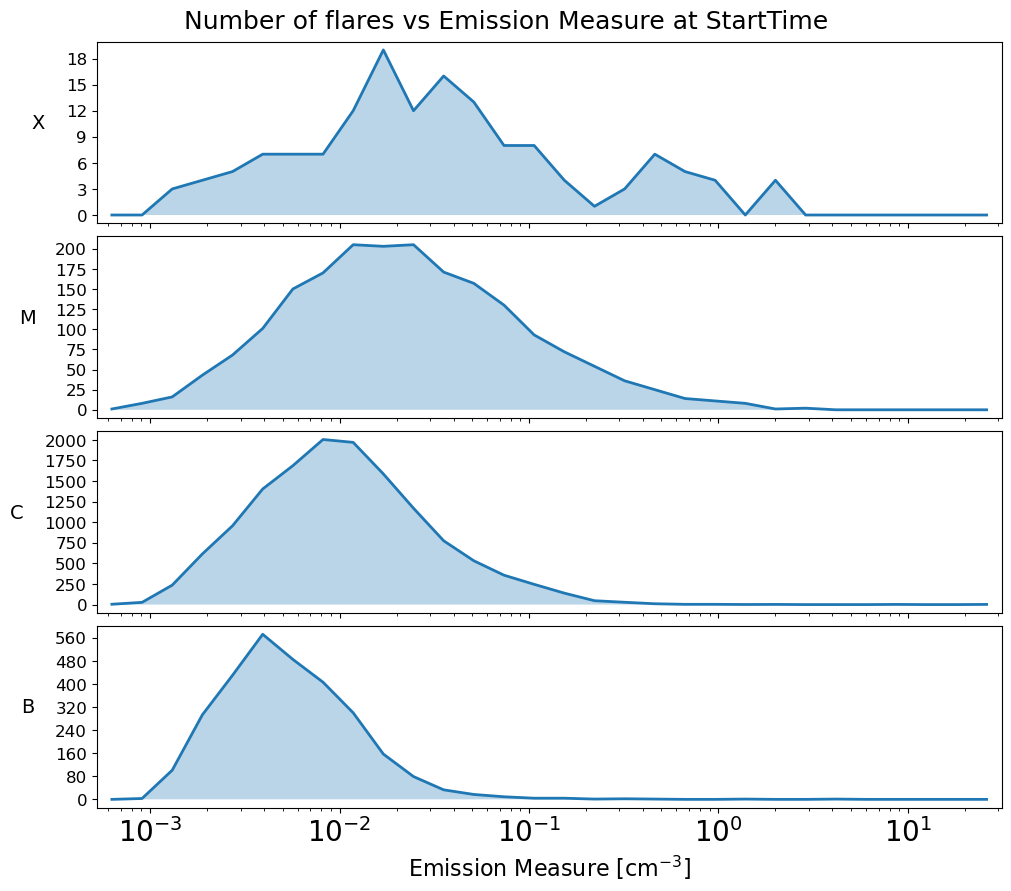

In [18]:
fig, EM_by_class =plot_em_counts_by_class(df_full_valid,
                                            df_flares_valid,
                                            classes=("X", "M", "C", "B"),
                                            time_column="StartTime",
                                            EM_col="EM_cor_norm",
                                            bins=30,
                                            graphics_dir=".",
                                            save_plot=True,
                                            plot_name=None,
                                            class_col="ClassLetter",
                                            x_min=None,
                                            x_max=None
                                        )

X 223
M 3347
C 28892
B 15412
Figure saved: ./em_counts_by_class_EndTime.png


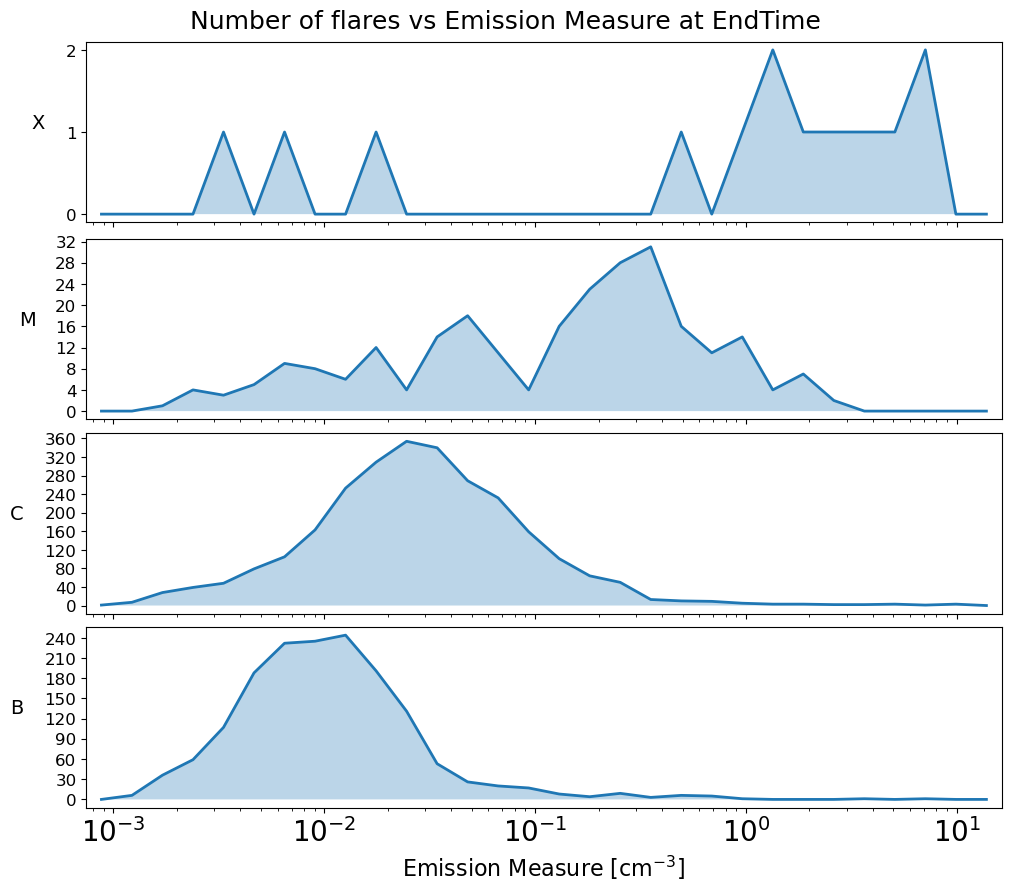

In [19]:
fig, EM_by_class =plot_em_counts_by_class(df_full_valid,
                                            df_flares_valid,
                                            classes=("X", "M", "C", "B"),
                                            time_column="EndTime",
                                            EM_col="EM_cor_norm",
                                            bins=30,
                                            graphics_dir=".",
                                            save_plot=True,
                                            plot_name=None,
                                            class_col="ClassLetter",
                                            x_min=None,
                                            x_max=None
                                        )

## Varias columnas a la vez EM

In [20]:
def plot_em_counts_multiple_times(
    df_full,
    df_flares,
    time_columns=("StartTime", "PeakTime"),
    classes=("X", "M", "C", "B", "A"),
    EM_col="EM_cor_norm",
    bins=30,
    graphics_dir=".",
    save_plot=True,
    plot_name=None,
    class_col="ClassLetter",
    x_min=None,
    x_max=None,
    colors=("tab:blue", "tab:orange")
):
    """
    Distribución del número de flares en función del Emission Measure (EM),
    para varias columnas de tiempo (por ejemplo StartTime y PeakTime),
    mostrando todas las curvas en el mismo gráfico por clase.
    """

    # --- Preparar datos ---
    df = df_full.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")

    df_flares = df_flares.copy()
    for tcol in time_columns:
        df_flares[tcol] = pd.to_datetime(df_flares[tcol])

    EM_by_class_time = {tcol: {} for tcol in time_columns}
    all_EM = []

    # --- Recolectar EM por clase y por columna de tiempo ---
    for flare_class in classes:
        df_class = df_flares[df_flares[class_col] == flare_class]

        for tcol in time_columns:
            EM_vals = []
            for _, flare in df_class.iterrows():
                flare_time = flare[tcol]
                if flare_time not in df.index:
                    continue
                EM = df.loc[flare_time, EM_col]
                if pd.notna(EM):
                    EM_vals.append(EM)
            EM_vals = np.array(EM_vals)
            EM_by_class_time[tcol][flare_class] = EM_vals
            all_EM.extend(EM_vals)

    if len(all_EM) == 0:
        print("No EM data available for selected classes and times")
        return None, EM_by_class_time

    all_EM = np.array(all_EM)

    # --- Límites X ---
    if x_min is None:
        x_min = np.nanmin(all_EM)
    if x_max is None:
        x_max = np.nanmax(all_EM)

    # --- Bins logarítmicos ---
    bins_edges = np.logspace(np.log10(x_min), np.log10(x_max), bins + 1)
    bin_centers = np.sqrt(bins_edges[:-1] * bins_edges[1:])

    # --- Crear figura ---
    fig, axes = plt.subplots(
        len(classes), 1,
        figsize=(10, 2.2 * len(classes)),
        sharex=True,
        constrained_layout=True
    )
    if len(classes) == 1:
        axes = [axes]

    # ============================
    # Plot por clase
    # ============================
    for ax, flare_class in zip(axes, classes):
        plotted_any = False

        for tcol, color in zip(time_columns, colors):
            EM_vals = EM_by_class_time[tcol][flare_class]
            if len(EM_vals) < 2:
                continue
            counts, _ = np.histogram(EM_vals, bins=bins_edges)
            ax.plot(bin_centers, counts, linewidth=2, label=tcol, color=color)
            ax.fill_between(bin_centers, counts, alpha=0.3, color=color)
            plotted_any = True

        ax.set_ylabel(flare_class, rotation=0, labelpad=20, fontsize=14)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.tick_params(axis="y", labelsize=12)

        if not plotted_any:
            ax.text(0.5, 0.5, "Not enough data",
                    ha="center", va="center", transform=ax.transAxes)
            ax.set_ylim(0, 1)

        ax.legend(fontsize=10)

    # --- Eje X ---
    axes[-1].set_xlabel(r"Emission Measure [cm$^{-3}$]", fontsize=16)
    axes[-1].set_xscale("log")
    axes[-1].set_xlim(x_min, x_max)

    # --- Título ---
    fig.suptitle(
        f"Number of flares vs Emission Measure",
        fontsize=18
    )

    # --- Guardar ---
    if plot_name is None:
        plot_name = "em_counts_multiple_times.png"

    if save_plot:
        output_path = os.path.join(graphics_dir, plot_name)
        plt.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved: {output_path}")

    plt.show()
    return fig, EM_by_class_time


Figure saved: ./em_counts_multiple_times.png


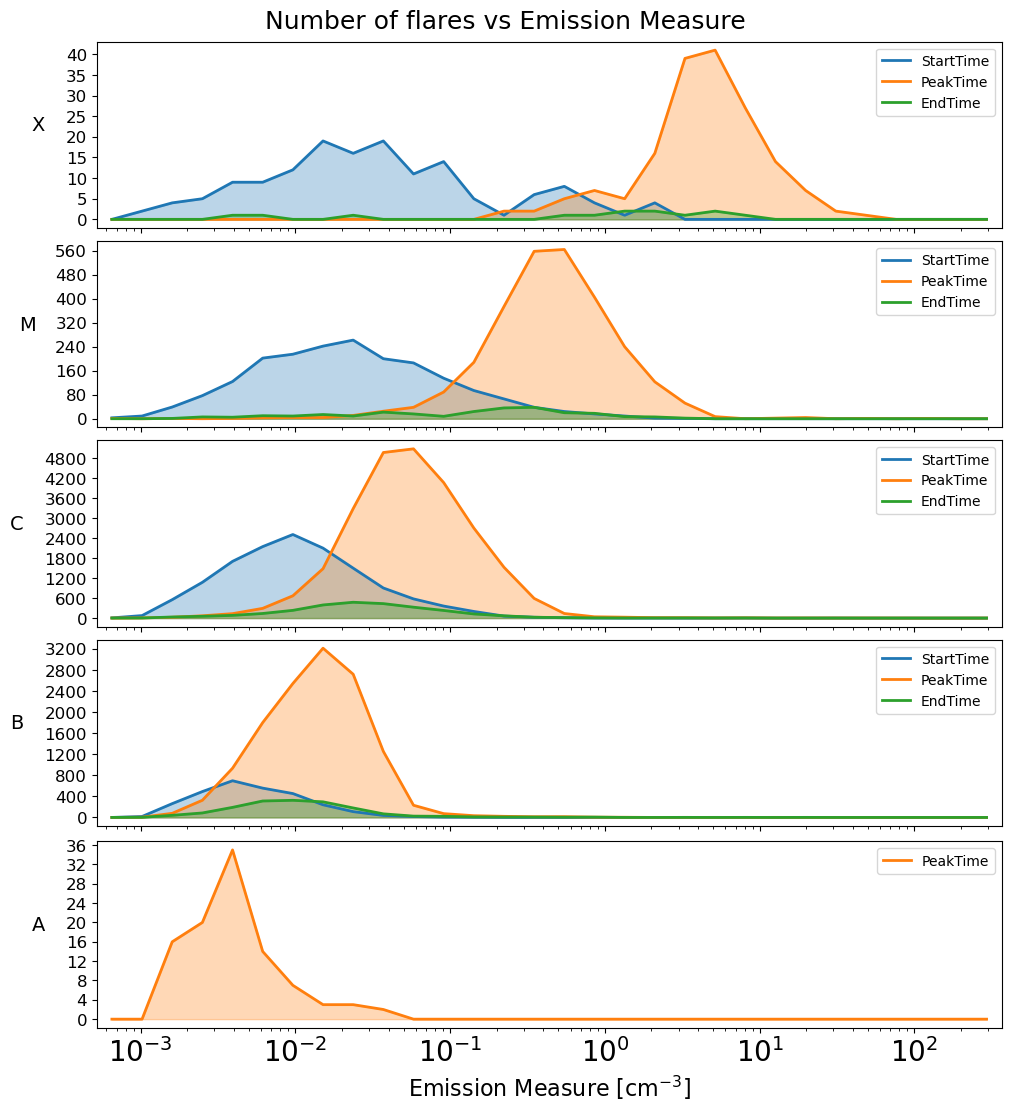

(<Figure size 1000x1100 with 5 Axes>,
 {'StartTime': {'X': array([3.49045419e-02, 7.30630102e-01, 1.99355348e-02, 3.65484101e-02,
          9.34433497e-01, 6.88657397e-02, 4.87330335e-02, 4.11950507e-02,
          3.70907473e-02, 3.49646298e-01, 5.86030905e-02, 6.20037200e-01,
          4.18444666e-01, 2.97595621e-02, 6.09410243e-03, 2.04953782e+00,
          1.48503571e-02, 5.15454967e-02, 5.83567136e-03, 6.08846177e-02,
          3.99859271e-01, 1.09150035e-01, 6.98591474e-03, 5.52910908e-02,
          6.08406038e-01, 1.72022377e+00, 1.66264869e-02, 1.03537038e-01,
          3.95940181e-02, 1.19588220e-02, 4.64920890e-01, 1.67062143e-01,
          1.03408708e-01, 8.15400962e-02, 8.00018586e-01, 4.04418139e-02,
          3.85543848e-01, 2.73379754e-02, 1.02872035e+00, 1.60712676e-02,
          4.19360175e-03, 2.05972160e+00, 2.06956543e-02, 7.69465132e-02,
          1.45629883e-02, 8.80530464e-02, 3.52101237e-02, 7.33940116e-02,
          5.86999970e-02, 9.18920638e-02, 4.20160221e-03

In [21]:
plot_em_counts_multiple_times(
    df_full_valid,
    df_flares_valid,
    time_columns=("StartTime", "PeakTime", "EndTime"),
    classes=("X", "M", "C", "B", "A"),
    EM_col="EM_cor_norm",
    bins=30,
    graphics_dir=".",
    save_plot=True,
    plot_name=None,
    class_col="ClassLetter",
    x_min=None,
    x_max=None,
    colors=("tab:blue", "tab:orange", "tab:green")
)

## Varias columnas a la vez T

In [22]:
def plot_temp_counts_multiple_times(
    df_full,
    df_flares,
    time_columns=("StartTime", "PeakTime"),
    classes=("X", "M", "C", "B", "A"),
    T_col="T_cor",
    bins=30,
    graphics_dir=".",
    save_plot=True,
    plot_name=None,
    class_col="ClassLetter",
    x_min=None,
    x_max=None,
    colors=("tab:blue", "tab:orange")
):
    """
    Comparación de la cantidad de flares por temperatura para distintas clases,
    usando varias columnas de tiempo en el mismo gráfico.
    
    Devuelve:
        fig: figura de matplotlib
        T_by_class_time: diccionario {columna_tiempo: {clase: array de temperaturas}}
    """

    # --- Preparar datos ---
    df = df_full.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")

    df_flares = df_flares.copy()
    for tcol in time_columns:
        df_flares[tcol] = pd.to_datetime(df_flares[tcol])

    T_by_class_time = {tcol: {} for tcol in time_columns}
    all_T = []

    # --- Recolectar temperaturas por clase y por columna de tiempo ---
    for flare_class in classes:
        df_class = df_flares[df_flares[class_col] == flare_class]

        for tcol in time_columns:
            T_vals = []
            for _, flare in df_class.iterrows():
                t = flare[tcol]
                if t in df.index:
                    T = df.loc[t, T_col]
                    if pd.notna(T):
                        T_vals.append(T)
            T_vals = np.array(T_vals)
            T_by_class_time[tcol][flare_class] = T_vals
            all_T.extend(T_vals)

    if len(all_T) == 0:
        print("No temperature data available for selected classes and times")
        return None, T_by_class_time

    all_T = np.array(all_T)

    # --- Límites X ---
    if x_min is None:
        x_min = np.nanmin(all_T)
    if x_max is None:
        x_max = np.nanmax(all_T)

    bins_edges = np.linspace(x_min, x_max, bins + 1)
    bin_centers = 0.5 * (bins_edges[:-1] + bins_edges[1:])

    # --- Crear figura ---
    fig, axes = plt.subplots(
        len(classes), 1,
        figsize=(10, 2.2 * len(classes)),
        sharex=True,
        constrained_layout=True
    )

    if len(classes) == 1:
        axes = [axes]

    # --- Plot por clase ---
    for ax, flare_class in zip(axes, classes):
        plotted_any = False

        for tcol, color in zip(time_columns, colors):
            T_vals = T_by_class_time[tcol][flare_class]
            if len(T_vals) < 2:
                continue

            counts, _ = np.histogram(T_vals, bins=bins_edges)
            ax.plot(bin_centers, counts, linewidth=2, label=tcol, color=color)
            ax.fill_between(bin_centers, counts, alpha=0.3, color=color)
            plotted_any = True

        ax.set_ylabel(flare_class, rotation=0, labelpad=20, fontsize=14)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.tick_params(axis="y", labelsize=12)

        if not plotted_any:
            ax.text(0.5, 0.5, "Not enough data",
                    ha="center", va="center", transform=ax.transAxes)
            ax.set_ylim(0, 1)

        ax.legend(fontsize=10)

    # --- Eje X ---
    axes[-1].set_xlabel("Temperature [MK]", fontsize=16)
    axes[-1].set_xlim(x_min, x_max)

    # --- Título ---
    fig.suptitle(
        "Number of flares vs Temperature",
        fontsize=18
    )

    # --- Guardar ---
    if plot_name is None:
        plot_name = "temp_counts_multiple_times.png"

    if save_plot:
        output_path = os.path.join(graphics_dir, plot_name)
        plt.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved: {output_path}")

    plt.show()
    return fig, T_by_class_time



Figure saved: ./temp_counts_multiple_times.png


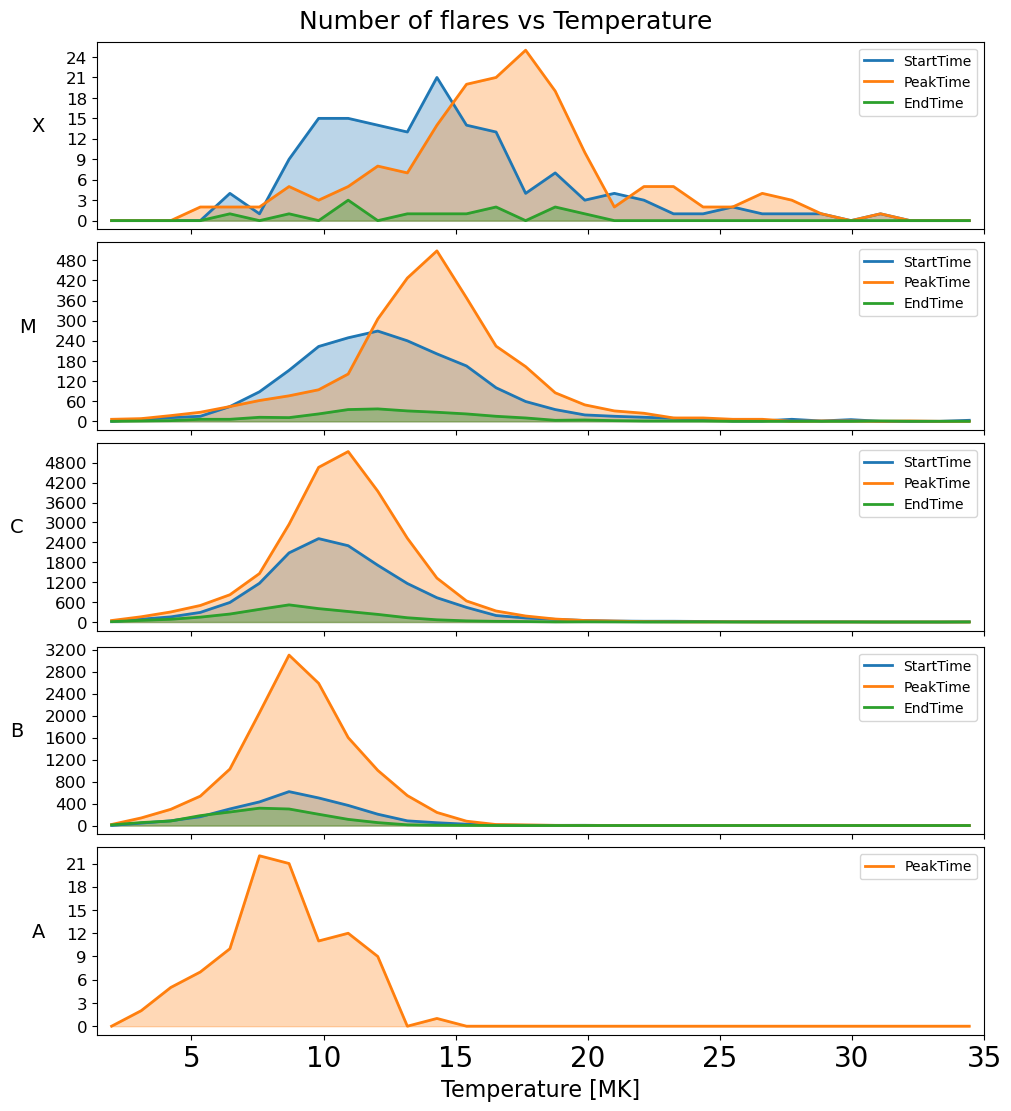

(<Figure size 1000x1100 with 5 Axes>,
 {'StartTime': {'X': array([ 8.4808859 , 30.86202521, 13.98372567, 14.26382776, 18.49140492,
          18.04455778, 14.10183434, 18.6576531 ,  9.84443981, 16.31697368,
          11.79445161, 13.67116302, 13.49251382, 11.7112643 ,  6.75647938,
          18.21211799,  8.56545772, 14.78895577, 14.44148759, 11.04922895,
          16.44146578, 21.29110068, 27.25655778, 15.09459633, 16.39916881,
          21.37206684, 19.0446402 , 14.55184491, 12.60093196, 13.20616658,
          16.88709048,  8.72544136, 13.6186234 , 13.49604996, 16.02789883,
          12.85389301, 18.51015488, 10.59043239, 13.85394803, 17.0327453 ,
          18.93524858, 26.75492181, 14.6053561 , 12.24198803, 10.30607487,
          11.71363611, 10.361658  , 15.74058433, 14.59297537,  9.27898424,
          21.02482884, 16.73667368, 15.29324891, 18.95195038, 16.7672322 ,
          13.83604371, 12.5039226 , 14.27303909, 13.73489809, 16.95511897,
          17.13293684, 13.88507546, 10.32855

In [23]:
plot_temp_counts_multiple_times(
    df_full_valid,
    df_flares_valid,
    time_columns=("StartTime", "PeakTime", "EndTime"),
    classes=("X", "M", "C", "B", "A"),
    T_col="T_cor",
    bins=30,
    graphics_dir=".",
    save_plot=True,
    plot_name=None,
    class_col="ClassLetter",
    x_min=None,
    x_max=35,
    colors=("tab:blue", "tab:orange", "tab:green")
)

## Funcion generalizada para cualquier variable

In [24]:
def plot_variable_counts_by_class(
    df_full,
    df_flares,
    classes=("X", "M", "C", "B", "A"),
    time_column="PeakTime",
    var_col="T_cor",                 # ← variable en el eje X
    var_label="Temperature [MK]",    # etiqueta eje X
    title_label="Temperature",       # para el título
    bins=30,
    graphics_dir=".",
    save_plot=True,
    plot_name=None,
    class_col="Class",
    x_min=None,
    x_max=None
):
    """
    Comparación de la cantidad de flares en función de una variable física
    (temperatura, EM, FAI, etc.) para distintas clases GOES.

    Los histogramas (counts reales) se representan como líneas continuas.

    Devuelve:
        fig : figura de matplotlib
        values_by_class : dict {clase: np.array}
    """

    # --- Preparar datos ---
    df = df_full.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")

    df_flares = df_flares.copy()
    df_flares[time_column] = pd.to_datetime(df_flares[time_column])

    values_by_class = {}

    # --- Recolectar todos los valores para límites automáticos ---
    all_vals = []
    for flare_class in classes:
        df_class = df_flares[df_flares[class_col] == flare_class]
        for _, flare in df_class.iterrows():
            t = flare[time_column]
            if t in df.index:
                v = df.loc[t, var_col]
                if pd.notna(v):
                    all_vals.append(v)

    all_vals = np.array(all_vals)

    if x_min is None:
        x_min = np.nanmin(all_vals)
    if x_max is None:
        x_max = np.nanmax(all_vals)

    # --- Binning común para todas las clases ---
    bins_edges = np.linspace(x_min, x_max, bins + 1)
    bin_centers = 0.5 * (bins_edges[:-1] + bins_edges[1:])

    # --- Crear figura ---
    fig, axes = plt.subplots(
        len(classes), 1,
        figsize=(10, 10),
        sharex=True,
        constrained_layout=True
    )

    if len(classes) == 1:
        axes = [axes]

    # --- Plot por clase ---
    for ax, flare_class in zip(axes, classes):

        df_class = df_flares[df_flares[class_col] == flare_class]

        vals = []
        for _, flare in df_class.iterrows():
            flare_time = flare[time_column]
            if flare_time in df.index:
                v = df.loc[flare_time, var_col]
                if pd.notna(v):
                    vals.append(v)

        vals = np.array(vals)
        values_by_class[flare_class] = vals

        if len(vals) < 2:
            ax.text(
                0.5, 0.5, "Not enough data",
                ha="center", va="center",
                transform=ax.transAxes
            )
            ax.set_ylim(0, 1)
            continue

        counts, _ = np.histogram(vals, bins=bins_edges)

        ax.plot(bin_centers, counts, linewidth=2)
        ax.fill_between(bin_centers, counts, alpha=0.3)

        ax.set_ylabel(
            f"{flare_class}",
            rotation=0,
            labelpad=20,
            fontsize=14
        )
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.tick_params(axis="y", labelsize=12)

    # --- Eje X ---
    axes[-1].set_xlabel(var_label, fontsize=16)
    axes[-1].set_xlim(x_min, x_max)

    # --- Título ---
    fig.suptitle(
        f"Number of flares vs {title_label} at {time_column}",
        fontsize=18
    )

    # --- Guardar ---
    if plot_name is None:
        plot_name = f"{var_col}_counts_by_class_{time_column}.png"

    if save_plot:
        output_path = os.path.join(graphics_dir, plot_name)
        plt.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved: {output_path}")

    plt.show()
    return fig, values_by_class


Figure saved: ./T_cor_counts_by_class_PeakTime.png


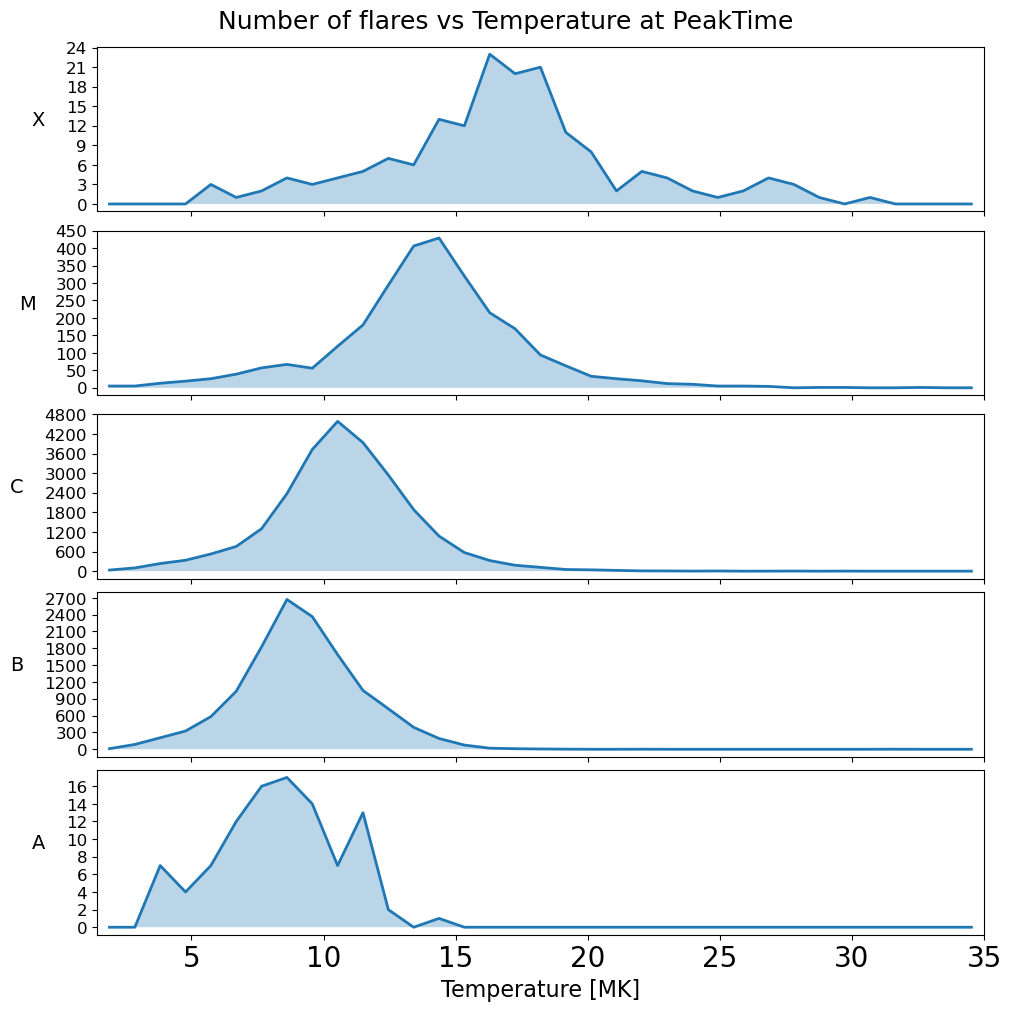

In [25]:
fig, T_by_class = plot_variable_counts_by_class(
    df_full=df_full_valid,
    df_flares=df_flares_valid,
    var_col="T_cor",
    var_label="Temperature [MK]",
    title_label="Temperature",
    time_column="PeakTime",
    class_col="ClassLetter",
    bins=35,
    x_min=None,
    x_max=35
)


Figure saved: ./EM_cor_norm_counts_by_class_PeakTime.png


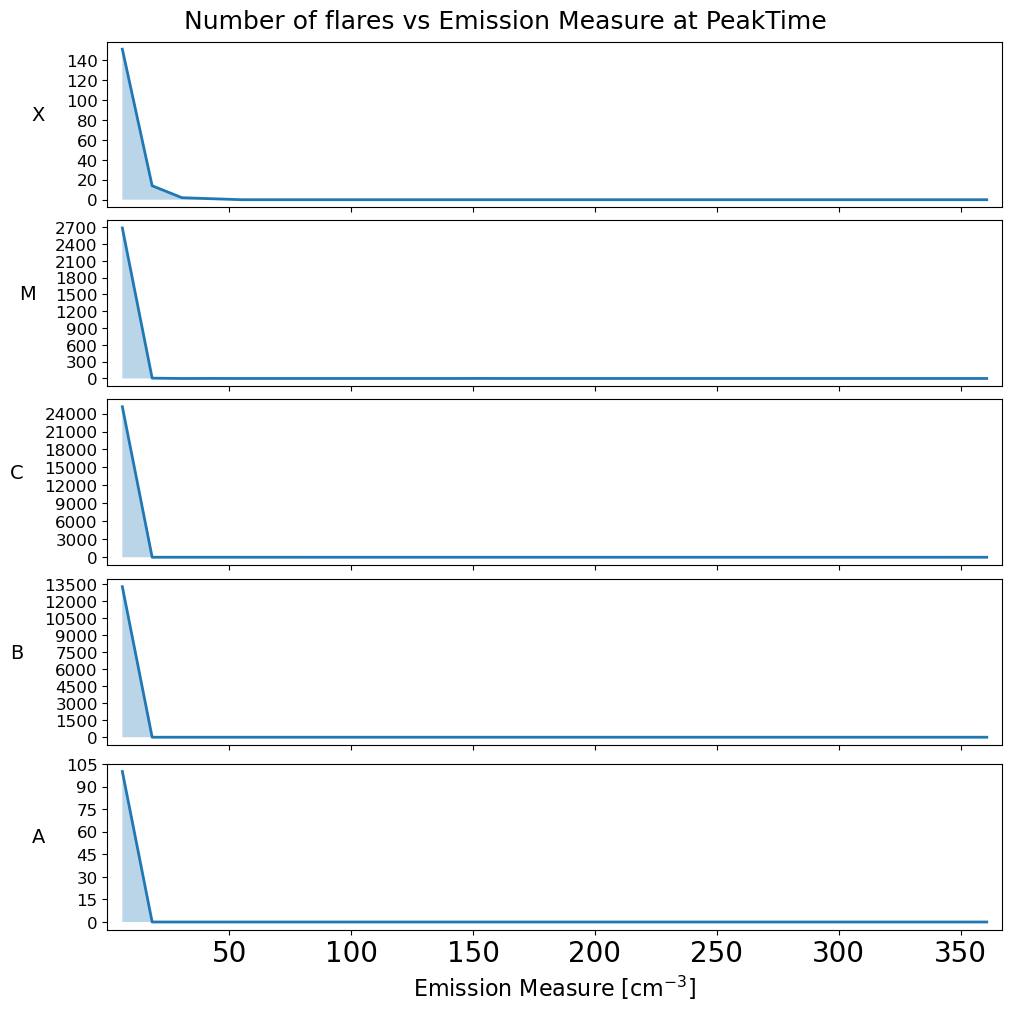

In [26]:
fig, EM_by_class = plot_variable_counts_by_class(
    df_full=df_full_valid,
    df_flares=df_flares_valid,
    var_col="EM_cor_norm",
    var_label=r"Emission Measure [cm$^{-3}$]",
    title_label="Emission Measure",
    time_column="PeakTime",
    class_col="ClassLetter",
    bins=30
)


## Test 3 - EM steps and KDE

In [35]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy.stats import gaussian_kde
import os


def plot_em_counts_multiple_times(
    df_full,
    df_flares,
    time_columns=("StartTime", "PeakTime", "EndTime"),
    classes=("X", "M", "C", "B", "A"),
    EM_col="EM_cor_norm",
    bins=30,
    graphics_dir=".",
    save_plot=True,
    plot_name=None,
    class_col="ClassLetter",
    x_min=None,
    x_max=None,
    colors=("tab:green", "tab:orange", "tab:blue")
):
    """
    Distribución del número de flares en función del Emission Measure (EM),
    usando histograma step + relleno + KDE suavizada.
    """

    # ---------------------------
    # Preparar datos
    # ---------------------------
    df = df_full.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")

    df_flares = df_flares.copy()
    for tcol in time_columns:
        df_flares[tcol] = pd.to_datetime(df_flares[tcol])

    EM_by_class_time = {tcol: {} for tcol in time_columns}
    all_EM = []

    for flare_class in classes:
        df_class = df_flares[df_flares[class_col] == flare_class]

        for tcol in time_columns:
            EM_vals = []
            for _, flare in df_class.iterrows():
                t = flare[tcol]
                if t not in df.index:
                    continue
                em = df.loc[t, EM_col]
                if pd.notna(em) and em > 0:
                    EM_vals.append(em)

            EM_vals = np.array(EM_vals)
            EM_by_class_time[tcol][flare_class] = EM_vals
            all_EM.extend(EM_vals)

    if len(all_EM) == 0:
        print("No EM data available for selected classes and times")
        return None, EM_by_class_time

    all_EM = np.array(all_EM)

    # ---------------------------
    # Límites X
    # ---------------------------
    if x_min is None:
        x_min = np.nanmin(all_EM)
    if x_max is None:
        x_max = np.nanmax(all_EM)

    bins_edges = np.logspace(np.log10(x_min), np.log10(x_max), bins + 1)
    bin_centers = np.sqrt(bins_edges[:-1] * bins_edges[1:])

    # ---------------------------
    # Figura
    # ---------------------------
    fig, axes = plt.subplots(
        len(classes), 1,
        figsize=(8, 2.3 * len(classes)),
        sharex=True,
        constrained_layout=True
    )
    if len(classes) == 1:
        axes = [axes]

    # ============================
    # Plot por clase
    # ============================
    for ax, flare_class in zip(axes, classes):
        plotted_any = False

        for tcol, color in zip(time_columns, colors):
            EM_vals = EM_by_class_time[tcol][flare_class]

            if len(EM_vals) < 5:
                continue

            # =========================
            # Histograma (counts)
            # =========================
            counts, _ = np.histogram(EM_vals, bins=bins_edges)

            ax.step(
                bin_centers,
                counts,
                where="mid",
                linewidth=2,
                color=color,
                label=tcol
            )

            ax.fill_between(
                bin_centers,
                counts,
                step="mid",
                alpha=0.25,
                color=color
            )

            # =========================
            # KDE en espacio log
            # =========================
            logEM = np.log10(EM_vals)

            kde = gaussian_kde(logEM)

            log_grid = np.linspace(
                np.log10(x_min),
                np.log10(x_max),
                500
            )

            kde_density = kde(log_grid)

            # Volver a EM
            EM_grid = 10**log_grid

            # Escalar KDE a counts por bin
            bin_widths = np.diff(bins_edges)
            mean_bin_width_log = np.mean(np.diff(np.log10(bins_edges)))

            kde_counts = kde_density * len(EM_vals) * mean_bin_width_log

            ax.plot(
                EM_grid,
                kde_counts,
                linewidth=2,
                color=color
            )


            plotted_any = True

        ax.set_ylabel(flare_class, rotation=0, labelpad=20, fontsize=14)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.tick_params(axis="y", labelsize=14)

        if not plotted_any:
            ax.text(
                0.5, 0.5, "Not enough data",
                ha="center", va="center",
                transform=ax.transAxes
            )
            ax.set_ylim(0, 1)

        ax.legend(fontsize=10)

    # ---------------------------
    # Ejes y título
    # ---------------------------
    axes[-1].set_xlabel(r"Emission Measure [cm$^{-3}$]", fontsize=16)
    axes[-1].set_xscale("log")
    axes[-1].set_xlim(x_min, x_max)

    fig.suptitle(
        "Number of flares vs Emission Measure",
        fontsize=18
    )

    # ---------------------------
    # Guardar
    # ---------------------------
    if plot_name is None:
        plot_name = "em_counts_multiple_times.png"

    if save_plot:
        output_path = os.path.join(graphics_dir, plot_name)
        plt.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved: {output_path}")

    plt.show()

    return fig, EM_by_class_time


Figure saved: ./em_counts_multiple_times.png


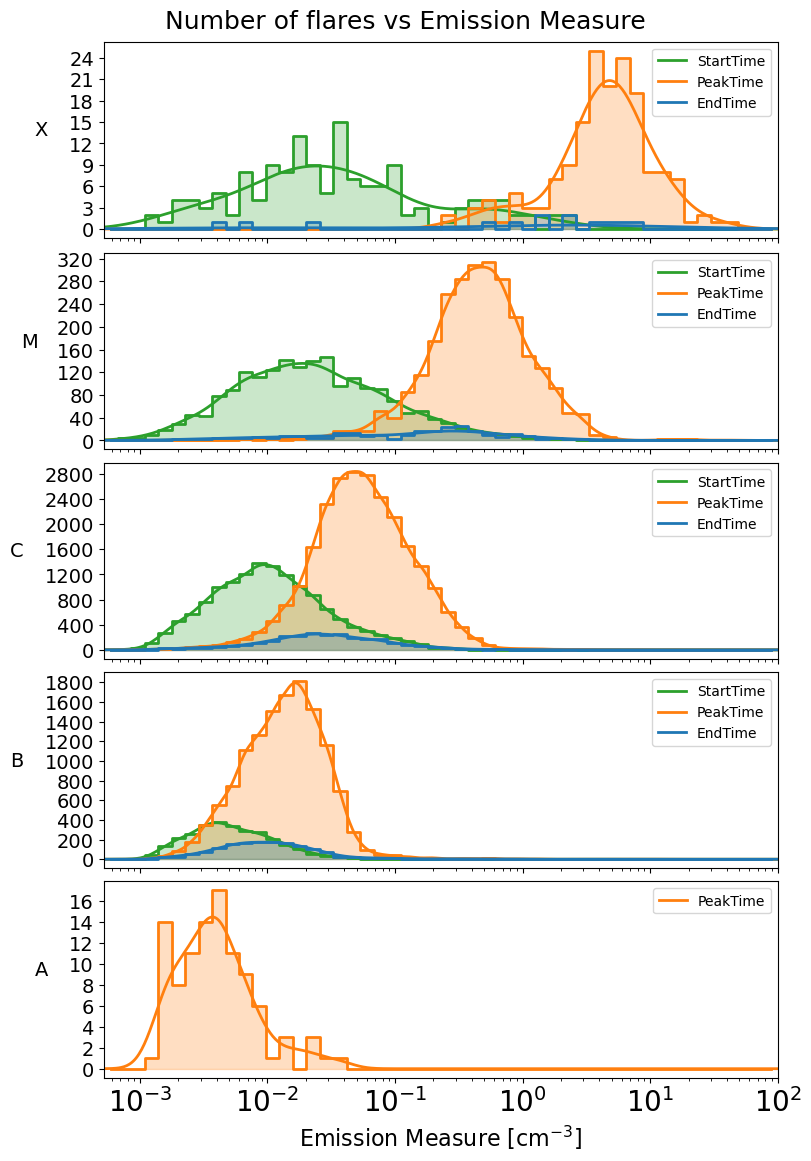

(<Figure size 800x1150 with 5 Axes>,
 {'StartTime': {'X': array([3.49045419e-02, 7.30630102e-01, 1.99355348e-02, 3.65484101e-02,
          9.34433497e-01, 6.88657397e-02, 4.87330335e-02, 4.11950507e-02,
          3.70907473e-02, 3.49646298e-01, 5.86030905e-02, 6.20037200e-01,
          4.18444666e-01, 2.97595621e-02, 6.09410243e-03, 2.04953782e+00,
          1.48503571e-02, 5.15454967e-02, 5.83567136e-03, 6.08846177e-02,
          3.99859271e-01, 1.09150035e-01, 6.98591474e-03, 5.52910908e-02,
          6.08406038e-01, 1.72022377e+00, 1.66264869e-02, 1.03537038e-01,
          3.95940181e-02, 1.19588220e-02, 4.64920890e-01, 1.67062143e-01,
          1.03408708e-01, 8.15400962e-02, 8.00018586e-01, 4.04418139e-02,
          3.85543848e-01, 2.73379754e-02, 1.02872035e+00, 1.60712676e-02,
          4.19360175e-03, 2.05972160e+00, 2.06956543e-02, 7.69465132e-02,
          1.45629883e-02, 8.80530464e-02, 3.52101237e-02, 7.33940116e-02,
          5.86999970e-02, 9.18920638e-02, 4.20160221e-03,

In [36]:
plot_em_counts_multiple_times(
    df_full_valid,
    df_flares_valid,
    time_columns=("StartTime", "PeakTime", "EndTime"),
    classes=("X", "M", "C", "B", "A"),
    EM_col="EM_cor_norm",
    bins=50,
    graphics_dir=".",
    save_plot=True,
    plot_name=None,
    class_col="ClassLetter",
    x_min=None,
    x_max=1e2,
    colors=("tab:green", "tab:orange", "tab:blue")
) 

## Test 3 - T steps and KDE

In [33]:
def plot_temp_counts_multiple_times(
    df_full,
    df_flares,
    time_columns=("StartTime", "PeakTime", "EndTime"),
    classes=("X", "M", "C", "B", "A"),
    T_col="T_cor",
    bins=30,
    graphics_dir=".",
    save_plot=True,
    plot_name=None,
    class_col="ClassLetter",
    x_min=None,
    x_max=35,
    colors=("tab:green", "tab:orange", "tab:blue")
):
    """
    Distribución del número de flares en función de la Temperatura,
    usando histograma step + relleno + KDE suavizada (espacio lineal).
    """

    # ---------------------------
    # Preparar datos
    # ---------------------------
    df = df_full.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")

    df_flares = df_flares.copy()
    for tcol in time_columns:
        df_flares[tcol] = pd.to_datetime(df_flares[tcol])

    T_by_class_time = {tcol: {} for tcol in time_columns}
    all_T = []

    for flare_class in classes:
        df_class = df_flares[df_flares[class_col] == flare_class]

        for tcol in time_columns:
            T_vals = []
            for _, flare in df_class.iterrows():
                t = flare[tcol]
                if t not in df.index:
                    continue
                T = df.loc[t, T_col]
                if pd.notna(T) and T > 0:
                    T_vals.append(T)

            T_vals = np.array(T_vals)
            T_by_class_time[tcol][flare_class] = T_vals
            all_T.extend(T_vals)

    if len(all_T) == 0:
        print("No temperature data available for selected classes and times")
        return None, T_by_class_time

    all_T = np.array(all_T)

    # ---------------------------
    # Límites X
    # ---------------------------
    if x_min is None:
        x_min = np.nanmin(all_T)
    if x_max is None:
        x_max = np.nanmax(all_T)

    bins_edges = np.linspace(x_min, x_max, bins + 1)
    bin_centers = 0.5 * (bins_edges[:-1] + bins_edges[1:])
    bin_width = bins_edges[1] - bins_edges[0]

    # ---------------------------
    # Figura
    # ---------------------------
    fig, axes = plt.subplots(
        len(classes), 1,
        figsize=(8, 2.3 * len(classes)),
        sharex=True,
        constrained_layout=True
    )
    if len(classes) == 1:
        axes = [axes]

    # ============================
    # Plot por clase
    # ============================
    for ax, flare_class in zip(axes, classes):
        plotted_any = False

        for tcol, color in zip(time_columns, colors):
            T_vals = T_by_class_time[tcol][flare_class]

            if len(T_vals) < 5:
                continue

            # -------------------------
            # Histograma (counts)
            # -------------------------
            counts, _ = np.histogram(T_vals, bins=bins_edges)

            ax.step(
                bin_centers,
                counts,
                where="mid",
                linewidth=2,
                color=color,
                label=tcol
            )

            ax.fill_between(
                bin_centers,
                counts,
                step="mid",
                alpha=0.25,
                color=color
            )

            # -------------------------
            # KDE en espacio lineal
            # -------------------------
            kde = gaussian_kde(T_vals)

            T_grid = np.linspace(x_min, x_max, 500)
            kde_density = kde(T_grid)

            # Escalar KDE a counts
            kde_counts = kde_density * len(T_vals) * bin_width

            ax.plot(
                T_grid,
                kde_counts,
                linewidth=2,
                color=color
            )

            plotted_any = True

        ax.set_ylabel(flare_class, rotation=0, labelpad=20, fontsize=14)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.tick_params(axis="y", labelsize=14)

        if not plotted_any:
            ax.text(
                0.5, 0.5, "Not enough data",
                ha="center", va="center",
                transform=ax.transAxes
            )
            ax.set_ylim(0, 1)

        ax.legend(fontsize=10)

    # ---------------------------
    # Ejes y título
    # ---------------------------
    axes[-1].set_xlabel("Temperature [MK]", fontsize=16)
    axes[-1].set_xlim(x_min, x_max)

    fig.suptitle(
        "Number of flares vs Temperature",
        fontsize=18
    )

    # ---------------------------
    # Guardar
    # ---------------------------
    if plot_name is None:
        plot_name = "temp_counts_multiple_times.png"

    if save_plot:
        output_path = os.path.join(graphics_dir, plot_name)
        plt.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved: {output_path}")

    plt.show()

    return fig, T_by_class_time


Figure saved: ./temp_counts_multiple_times.png


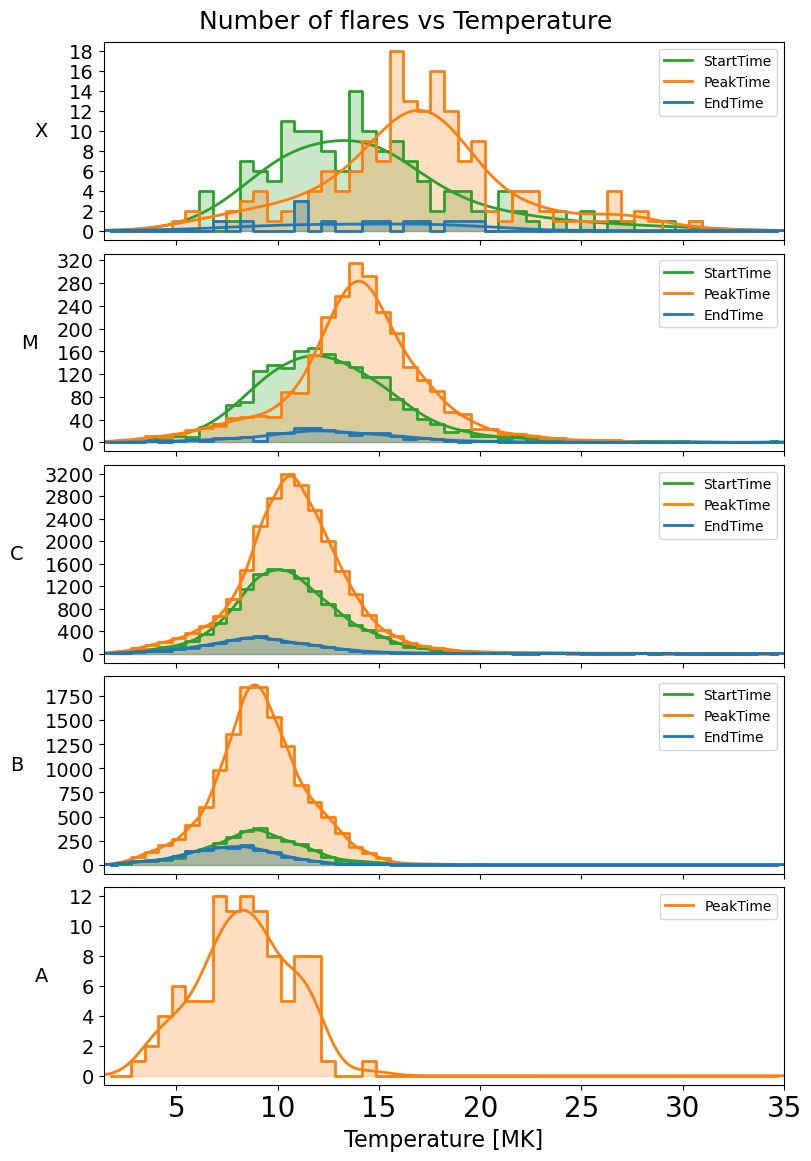

(<Figure size 800x1150 with 5 Axes>,
 {'StartTime': {'X': array([ 8.4808859 , 30.86202521, 13.98372567, 14.26382776, 18.49140492,
          18.04455778, 14.10183434, 18.6576531 ,  9.84443981, 16.31697368,
          11.79445161, 13.67116302, 13.49251382, 11.7112643 ,  6.75647938,
          18.21211799,  8.56545772, 14.78895577, 14.44148759, 11.04922895,
          16.44146578, 21.29110068, 27.25655778, 15.09459633, 16.39916881,
          21.37206684, 19.0446402 , 14.55184491, 12.60093196, 13.20616658,
          16.88709048,  8.72544136, 13.6186234 , 13.49604996, 16.02789883,
          12.85389301, 18.51015488, 10.59043239, 13.85394803, 17.0327453 ,
          18.93524858, 26.75492181, 14.6053561 , 12.24198803, 10.30607487,
          11.71363611, 10.361658  , 15.74058433, 14.59297537,  9.27898424,
          21.02482884, 16.73667368, 15.29324891, 18.95195038, 16.7672322 ,
          13.83604371, 12.5039226 , 14.27303909, 13.73489809, 16.95511897,
          17.13293684, 13.88507546, 10.328553

In [34]:
plot_temp_counts_multiple_times(
    df_full_valid,
    df_flares_valid,
    time_columns=("StartTime", "PeakTime", "EndTime"),
    classes=("X", "M", "C", "B", "A"),
    T_col="T_cor",
    bins=50,
    graphics_dir=".",
    save_plot=True,
    plot_name=None,
    class_col="ClassLetter",
    x_min=None,
    x_max=35,
    colors=("tab:green", "tab:orange", "tab:blue")
)